# A02 Python、数组、单位与可追溯数据

**跟随操作：入门；独立解释：基础。** 先读[A01](A01.ipynb)，操作步骤见[统一运行说明](../docs/RUNNING.md)。

目标：识别记录ID、数组形状、逐元与矩阵运算，使用显式单位并保存可核对的输入和结果。本课仅用合成数值，不是实验测量、能量预测或电子结构计算。

## 当前课程状态（2026-10-19）

五课已完成真实Colab默认/修改参数共10轮运行、私有依赖安装、手工参数修改、结果重载及Drive另存副本。五份原生下载的Notebook已核验；其内嵌结果ZIP均与云端结果逐字节一致。单独点击ZIP链接下载仍未验；新RHF仍未验收（NOT_EXECUTED）。

本次仅更新公开导航和状态文字，不改变科学代码、样本、内置wheel及运行器。保存的科学输出和Colab内置原课中的旧状态文字属于历史快照，以本页说明及docs/STATUS.md为准；FAIL、DIAGNOSTIC及NOT_ASSESSED边界不变。

GitHub只显示静态内容；交互计算使用独立Colab适配。公开页面/固定ref入口首次同步后单独核对；Binder、其它账号/环境、试学与独立解释能力未验收。

[课程首页](../README.md) · [交互运行说明](../docs/RUNNING.md) · [完成与未验收范围](../docs/STATUS.md)

## 学习与验收范围

五课已完成真实Colab默认/修改参数共10轮运行、私有依赖安装、手工参数修改、结果重载及Drive另存副本。五份原生下载的Notebook已核验；其内嵌结果ZIP均与云端结果逐字节一致。单独点击ZIP链接下载仍未验；新RHF仍未验收（NOT_EXECUTED）。

本次仅更新公开导航和状态文字，不改变科学代码、样本、内置wheel及运行器。保存的科学输出和Colab内置原课中的旧状态文字属于历史快照，以本页说明及docs/STATUS.md为准；FAIL、DIAGNOSTIC及NOT_ASSESSED边界不变。

GitHub只显示静态内容；交互计算使用独立Colab适配。公开页面/固定ref入口首次同步后单独核对；Binder、其它账号/环境、试学与独立解释能力未验收。

[五课入口](../README.md) · [本课Colab适配](../colab/A02-colab.ipynb)

In [1]:
import hashlib, json, uuid
from pathlib import Path
import numpy as np
from IPython.display import display, HTML, Image

roots=[p for base in (Path.cwd(),*Path.cwd().parents)
       for p in (base,base/"learning/common_guide")
       if (p/"lesson-manifest.json").is_file()
       and json.loads((p/"lesson-manifest.json").read_text("utf-8")).get("group")=="P1_COMMON"]
if not roots:raise FileNotFoundError("请从完整项目或公共导学目录启动；查看统一运行说明。")
guide_root=roots[0];manifest=json.loads((guide_root/"lesson-manifest.json").read_text("utf-8"))
for item in manifest["inputs"]:
    if hashlib.sha256((guide_root/item["file"]).read_bytes()).hexdigest()!=item["sha256"]:
        raise ValueError("导学样本哈希不符")
workspace=guide_root/"outputs"/("study-"+uuid.uuid4().hex)
workspace.mkdir(parents=True,exist_ok=False)
print("导学输入哈希PASS；结果写入全新课程内目录；不连接计算后端。")

导学输入哈希PASS；结果写入全新课程内目录；不连接计算后端。


## 1. 变量、列表、ID与数组

JSON中每个record_id对应一个能量演示值。先读原值，再转数组；缺失、布尔值、NaN和Infinity不能悄悄当普通观测。过滤数据时必须同步保留ID，不能分别排序造成错配。

In [2]:
data=json.loads((guide_root/"samples/intro-data.json").read_text("utf-8"))
ids=[row["record_id"] for row in data["records"]]
values=np.array([row["energy"] for row in data["records"]],dtype=float)
if values.ndim!=1 or len(ids)!=len(values) or not np.isfinite(values).all():raise ValueError("ID、形状或有限性不符")
assert len(set(ids))==len(ids)==4
print("记录ID：",ids,"；数组形状：",values.shape,"；来源：SYNTHETIC_ANALYTIC")
x=np.array([0.,1.,2.])
assert np.array_equal(x*x,[0,1,4]) and float(x@x)==5
print("逐元平方：",(x*x).tolist(),"；点积：",float(x@x))
A=np.array([[1.,0.],[0.,2.]])
assert (A@np.array([1.,2.])).tolist()==[1.,4.]
print("矩阵@向量需要对齐维度；二维广播不能替代记录ID核对。")

记录ID： ['sample-1', 'sample-2', 'sample-3', 'sample-4'] ；数组形状： (4,) ；来源：SYNTHETIC_ANALYTIC
逐元平方： [0.0, 1.0, 4.0] ；点积： 5.0
矩阵@向量需要对齐维度；二维广播不能替代记录ID核对。


## 2. 显式单位与换算

$$1\ \mathrm{Eh}=2625.4996394799\ \mathrm{kJ/mol}$$

使用核心的冻结adp-units-v1常数，保留原值、原单位和转换因子。不能因数字大小猜单位，也不能直接混加不同单位。

把ENERGY_UNIT由hartree改为kJ/mol再运行；显示数值和纵轴单位改变，换回Eh后应一致。这只是单位表示变化，不生成新的量子能量。

In [3]:
from decimal import Decimal
from ai4orgchem_data_processing.units import convert_energy
ENERGY_UNIT = "hartree"
if ENERGY_UNIT not in ("hartree","kJ/mol"):raise ValueError("本练习只支持hartree或kJ/mol")
assert Decimal(convert_energy(1,"hartree","kJ/mol")["target_value"])==Decimal("2625.4996394799")
converted=[convert_energy(float(v),data["unit"],ENERGY_UNIT) for v in values]
shown=np.array([float(item["target_value"]) for item in converted])
restored=np.array([float(convert_energy(Decimal(item["target_value"]),ENERGY_UNIT,"hartree")["target_value"]) for item in converted])
np.testing.assert_allclose(restored,values,atol=1e-12,rtol=1e-12)
display(HTML("<table><tr><th>ID</th><th>原值 (Eh)</th><th>显示值</th><th>单位</th></tr>"+"".join(f"<tr><td>{id_}</td><td>{v:g}</td><td>{s:.8g}</td><td>{ENERGY_UNIT}</td></tr>" for id_,v,s in zip(ids,values,shown))+"</table>"))
LESSON="A02";PARAMETER=ENERGY_UNIT

ID,原值 (Eh),显示值,单位
sample-1,-0.5,-0.5,hartree
sample-2,0,0,hartree
sample-3,0.5,0.5,hartree
sample-4,1,1,hartree


## 3. 拒绝错误输入，不静默修复

未知/空单位、非有限值和布尔值应拒绝；ID与数值长度不一致也应停止。本单元显式核对错误，不把失败记录填零、删掉或伪造为有效数据。

In [4]:
from ai4orgchem_data_processing.errors import InputRejected
refusals=[]
for value,unit,expected in [(1,"","UNSUPPORTED_UNIT"),(float("nan"),"hartree","NONFINITE_VALUE"),(True,"hartree","INVALID_TYPE")]:
    try:convert_energy(value,unit,"hartree")
    except InputRejected as exc:
        assert str(exc.code)==expected;refusals.append(expected)
    else:raise AssertionError("错误输入没有被拒绝")
def check_alignment(keys,array):
    if len(keys)!=len(array):raise ValueError("ID与值未对齐")
try:check_alignment(ids[:-1],values)
except ValueError:refusals.append("ID_VALUE_LENGTH_MISMATCH")
else:raise AssertionError("错配没有被拒绝")
print("按预期拒绝：",refusals)

按预期拒绝： ['UNSUPPORTED_UNIT', 'NONFINITE_VALUE', 'INVALID_TYPE', 'ID_VALUE_LENGTH_MISMATCH']


## 4. 数据图与文件保存

每个柱对应一个合成记录，纵轴只使用当前选定的一种单位。不能把两个单位的原始数字画在同一能量轴后直接比较。图由实际数值生成，不使用图片生成模型造数据。

CSV保存ID、原值/单位、换算值/单位；JSON保存规则和拒绝摘要。换回原单位的数值一致，不代表实验精度、模型性能或科学资格已认证。

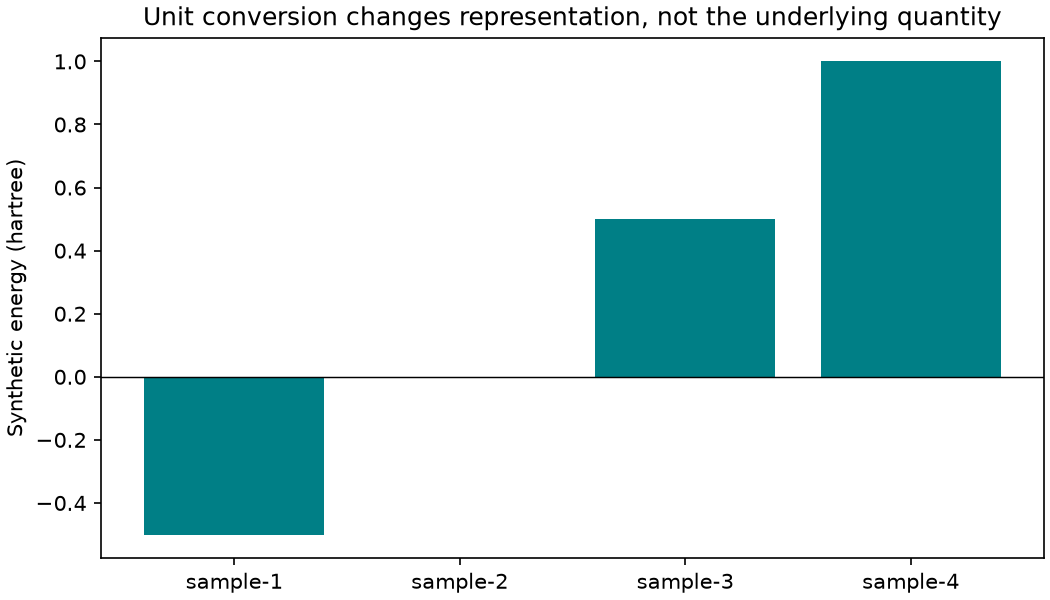

151

In [5]:
import csv
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
fig=Figure(figsize=(7,4),layout="constrained");FigureCanvasAgg(fig)
ax=fig.subplots();ax.bar(ids,shown,color="#007f86");ax.axhline(0,color="black",linewidth=.7)
ax.set_ylabel("Synthetic energy ("+ENERGY_UNIT+")");ax.set_title("Unit conversion changes representation, not the underlying quantity")
fig.savefig(workspace/"units-demo.png",dpi=150)
display(Image(filename=str(workspace/"units-demo.png")))
with (workspace/"rows.csv").open("w",newline="",encoding="utf-8") as f:
    writer=csv.writer(f);writer.writerow(["record_id","original_value","original_unit","value","unit"])
    writer.writerows((id_,float(v),data["unit"],float(s),ENERGY_UNIT) for id_,v,s in zip(ids,values,shown))
(workspace/"checks.json").write_text(json.dumps({"unit_roundtrip":"PASS","rejections":refusals,"policy":"adp-units-v1"}),encoding="utf-8")

In [6]:
import zipfile
input_name="course-map.json" if LESSON=="A01" else "intro-data.json"
(workspace/"input.json").write_bytes((guide_root/"samples"/input_name).read_bytes())
summary={"lesson":LESSON,"analysis":"PASS","parameter":PARAMETER,
         "new_quantum_calls":0,"new_rhf":"NOT_EXECUTED","teaching_effectiveness":"NOT_EVALUATED"}
(workspace/"settings.json").write_text(json.dumps({"lesson":LESSON,"parameter":PARAMETER},ensure_ascii=False,indent=2),encoding="utf-8")
(workspace/"lesson-result.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding="utf-8")
assert json.loads((workspace/"lesson-result.json").read_text("utf-8"))==summary
inventory=[{"file":p.name,"sha256":hashlib.sha256(p.read_bytes()).hexdigest()} for p in sorted(workspace.iterdir()) if p.is_file()]
(workspace/"manifest.json").write_text(json.dumps(inventory,indent=2),encoding="utf-8")
archive=workspace/"lesson-results.zip"
with zipfile.ZipFile(archive,"x",compression=zipfile.ZIP_DEFLATED) as z:
    for item in inventory:z.write(workspace/item["file"],item["file"])
    z.write(workspace/"manifest.json","manifest.json")
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None
    for item in inventory:assert hashlib.sha256(z.read(item["file"])).hexdigest()==item["sha256"]
print("输入、设置、结果摘要与ZIP已保存并重载/校验；到outputs中新建study目录下载lesson-results.zip。")

输入、设置、结果摘要与ZIP已保存并重载/校验；到outputs中新建study目录下载lesson-results.zip。


## 自测与下一步

为什么换单位后数值会变？为什么ID比行号更适合追踪记录？为什么不能把NaN填零继续算？

参考：尺度改变而量不变；行可能排序/过滤，稳定ID用于关联；零与未知不是同一含义。下一步读[B03表格拟合](B03.ipynb)，再进入[F01账本](F01.ipynb)与[F02保存水分子](F02.ipynb)。

本课没有新RHF，没有训练预测模型，也没有用户试学；自动断言与独立解释分别评价。